# Librerias

In [ ]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, classification_report
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, mean_squared_error
import numpy as np
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.svm import SVR
from sklearn.neighbors import KNeighborsRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.metrics import mean_squared_error, r2_score, roc_auc_score, roc_curve, confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt
import seaborn as sns

# Code 1

Error cuadrático medio (MSE): 1276.7050454777461
Raíz del error cuadrático medio (RMSE): 35.731009578204564
R^2 Score: 0.8181999673714166
Predicciones guardadas en 'predicciones_demanda.csv'
   Demanda_Predicha
0        284.005719
1        423.867775
2        356.033842
3        410.161227
4        273.146292
5        310.357056
6        317.975043
7        341.449537
8        289.716361
9        353.596404


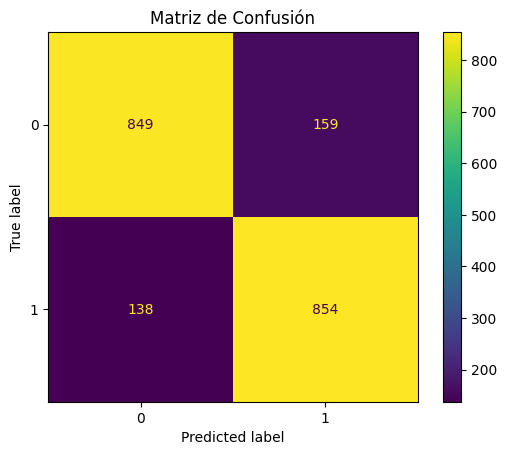

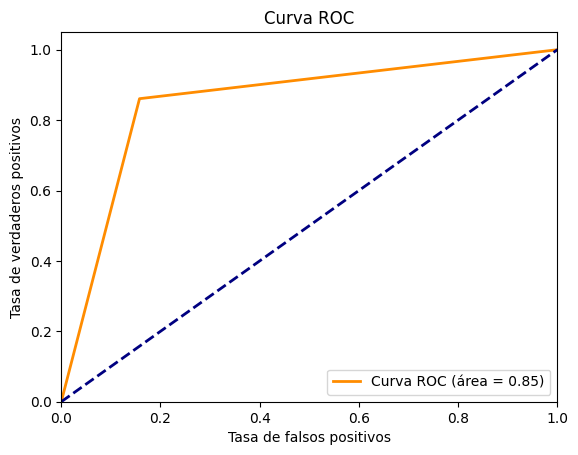

In [ ]:
# Cargar el conjunto de datos 📊
df = pd.read_csv('/content/inventario_con_datos_rfid_222.csv')

# Convertir las variables categóricas en variables dummy 🏷️
df = pd.get_dummies(df, columns=['Categoria', 'Estacion'], drop_first=True)

# Verificar si existe la columna 'Fecha' 📅
if 'Fecha' in df.columns:
    # Crear características adicionales si es necesario (Ejemplo) 🛠️
    df['Mes'] = pd.to_datetime(df['Fecha']).dt.month
    df['Año'] = pd.to_datetime(df['Fecha']).dt.year
    df = df.drop(['Fecha'], axis=1)

# Definir las características (X) y la variable objetivo (y) 🎯
X = df.drop(['ProductoID', 'Demanda'], axis=1)
y = df['Demanda']

# Normalizar las características 🧮
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Dividir los datos en conjuntos de entrenamiento y prueba 🏋️‍♂️
X_train, X_test, y_train, y_test = train_test_split(X_scaled, y, test_size=0.2, random_state=42)

# Definir el modelo de bosque aleatorio 🌳
forest = RandomForestRegressor(random_state=42, n_jobs=-1)

# Definir los parámetros para GridSearchCV 🔍
param_grid = {
    'n_estimators': [50, 100, 200],
    'max_depth': [None, 10, 20, 30],
    'min_samples_split': [2, 5, 10]
}

# Realizar la búsqueda de hiperparámetros con validación cruzada 🤖
grid_search = GridSearchCV(forest, param_grid, cv=5, scoring='neg_mean_squared_error', n_jobs=-1)
grid_search.fit(X_train, y_train)

# Mejor modelo 🏆
best_forest = grid_search.best_estimator_

# Hacer predicciones sobre el conjunto de prueba 🔮
y_pred = best_forest.predict(X_test)

# Evaluar el modelo 📈
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)
print(f"Error cuadrático medio (MSE): {mse}")
print(f"Raíz del error cuadrático medio (RMSE): {rmse}")
print(f"R^2 Score: {r2}")

# Guardar las predicciones en un archivo CSV 💾
# predicciones = pd.DataFrame({'Demanda_Real': y_test, 'Demanda_Predicha': y_pred})
predicciones = pd.DataFrame({'Demanda_Predicha': y_pred})
predicciones.to_csv('/content/3predicciones_demanda.csv', index=False)
print("Predicciones guardadas en 'predicciones_demanda.csv'")

# Visualizar los primeros 10 datos del DataFrame de predicciones 🔍
print(predicciones.head(10))

# Crear la matriz de confusión ❌⭕
# Convertir a clasificación binaria para la matriz de confusión
y_test_bin = y_test > y_test.median()
y_pred_bin = y_pred > y_test.median()
cm = confusion_matrix(y_test_bin, y_pred_bin)
disp = ConfusionMatrixDisplay(confusion_matrix=cm)
disp.plot()
plt.title("Matriz de Confusión")
plt.show()

# Crear la curva ROC 📉
fpr, tpr, _ = roc_curve(y_test_bin, y_pred_bin)
roc_auc = roc_auc_score(y_test_bin, y_pred_bin)
plt.figure()
plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'Curva ROC (área = {roc_auc:.2f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('Tasa de falsos positivos')
plt.ylabel('Tasa de verdaderos positivos')
plt.title('Curva ROC')
plt.legend(loc="lower right")
plt.show()

# Code 2

Regresor: RandomForest (Impacto de Promoción)
Error cuadrático medio (MSE): 1.3098362123837708
Raíz del error cuadrático medio (RMSE): 1.1444807610369738
R²: 0.9999542277930393


Regresor: DecisionTree (Impacto de Promoción)
Error cuadrático medio (MSE): 5.841375
Raíz del error cuadrático medio (RMSE): 2.416893667499669
R²: 0.9997958732375033


Regresor: GradientBoosting (Impacto de Promoción)
Error cuadrático medio (MSE): 5.44576995587828
Raíz del error cuadrático medio (RMSE): 2.3336173542117566
R²: 0.9998096976498863


Regresor: SVR (Impacto de Promoción)
Error cuadrático medio (MSE): 654.4041762426039
Raíz del error cuadrático medio (RMSE): 25.58132475542664
R²: 0.9771318557940988


Regresor: KNN (Impacto de Promoción)
Error cuadrático medio (MSE): 7.312300000000001
Raíz del error cuadrático medio (RMSE): 2.7041264763320525
R²: 0.9997444717852552


Predicciones guardadas en 'predicciones_impacto_promocion.csv'
Mejor regresor (Impacto de Promoción): RandomForestRegressor(random_stat

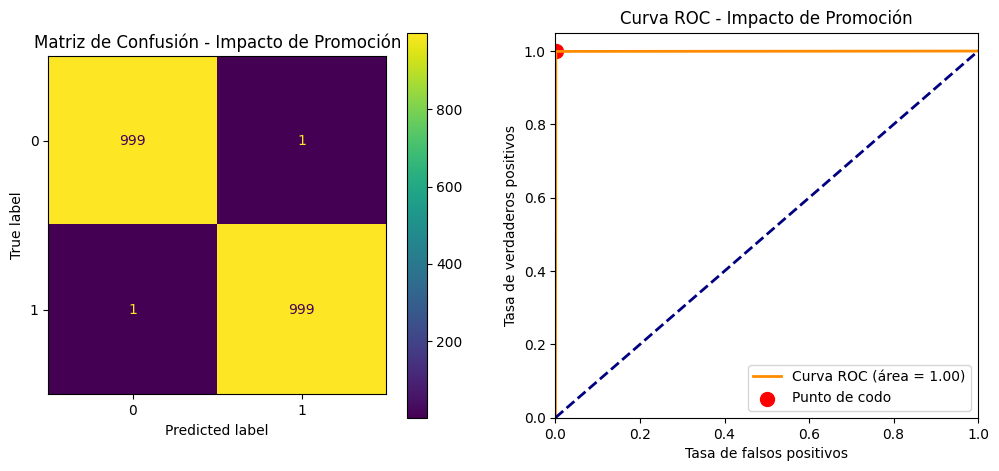

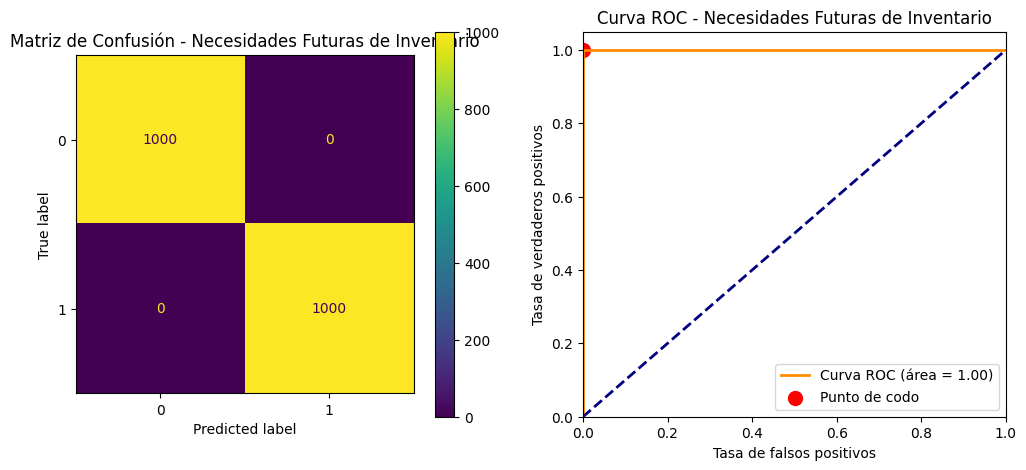

In [ ]:
# Cargar el conjunto de datos 📊
df = pd.read_csv('/content/inventario_con_datos_rfid_222.csv')

# Convertir las variables categóricas en variables dummy 🏷️
df = pd.get_dummies(df, columns=['Categoria', 'Estacion'], drop_first=True)

# Definir y normalizar las características (X) y la variable objetivo (y) para impacto de la promoción 🎯
X1 = df[['Promocion', 'VentasHistoricas', 'VentasDurantePromocion', 'VentasPostPromocion']]
y1 = df['InventarioVentas']
scaler1 = StandardScaler()
X1_scaled = scaler1.fit_transform(X1)

# Dividir los datos en conjuntos de entrenamiento y prueba 🏋️‍♂️
X1_train, X1_test, y1_train, y1_test = train_test_split(X1_scaled, y1, test_size=0.2, random_state=42)

# Tarea 1: Impacto de la Promoción
# Objetivo principal es evaluar el impacto de la promoción en las ventas y predecir el inventario necesario después de la promoción.
# Definir los regresores a evaluar 🤖
regressors = {
    'RandomForest': RandomForestRegressor(random_state=42),
    'DecisionTree': DecisionTreeRegressor(random_state=42),
    'GradientBoosting': GradientBoostingRegressor(random_state=42),
    'SVR': SVR(),
    'KNN': KNeighborsRegressor()
}

# Evaluar el rendimiento de cada regresor para el impacto de la promoción 📊
best_regressor1 = None
best_rmse1 = float('inf')

for name, reg in regressors.items():
    reg.fit(X1_train, y1_train)
    y1_pred = reg.predict(X1_test)
    mse = mean_squared_error(y1_test, y1_pred)
    rmse = np.sqrt(mse)
    print(f"Regresor: {name} (Impacto de Promoción)")
    print(f"Error cuadrático medio (MSE): {mse}")
    print(f"Raíz del error cuadrático medio (RMSE): {rmse}")
    print(f"R²: {r2_score(y1_test, y1_pred)}")
    print("\n")

    if rmse < best_rmse1:
        best_rmse1 = rmse
        best_regressor1 = reg

# Guardar las predicciones del mejor regresor para impacto de promoción en un archivo CSV 💾
best_pred1 = best_regressor1.predict(X1_test)
predicciones1 = pd.DataFrame({'Impacto_Promocion': best_pred1})
predicciones1.to_csv('/content/predicciones_impacto_promocion.csv', index=False)

print("Predicciones guardadas en 'predicciones_impacto_promocion.csv'")
print(f"Mejor regresor (Impacto de Promoción): {best_regressor1}")
print(f"Mejor RMSE (Impacto de Promoción): {best_rmse1}")

# *********************************************************************************************************************

# Tarea 2: Necesidades Futuras de Inventario
# objetivo aquí es prever las necesidades futuras de inventario basadas en diferentes características
# Definir y normalizar las características (X) y la variable objetivo (y) para necesidades futuras de inventario 📦
X2 = df[['Promocion', 'InventarioAlmacenamiento', 'InventarioRecepcion', 'VentasDurantePromocion', 'VentasPostPromocion']]
y2 = df['InventarioAlmacenamiento']
scaler2 = StandardScaler()
X2_scaled = scaler2.fit_transform(X2)

# Dividir los datos en conjuntos de entrenamiento y prueba 🏋️‍♂️
X2_train, X2_test, y2_train, y2_test = train_test_split(X2_scaled, y2, test_size=0.2, random_state=42)

# Evaluar el rendimiento de cada regresor para necesidades futuras de inventario 📊
best_regressor2 = None
best_rmse2 = float('inf')
print()
print("========================================================================================")
print()
for name, reg in regressors.items():
    reg.fit(X2_train, y2_train)
    y2_pred = reg.predict(X2_test)
    mse = mean_squared_error(y2_test, y2_pred)
    rmse = np.sqrt(mse)
    print(f"Regresor: {name} (Necesidades Futuras de Inventario)")
    print(f"Error cuadrático medio (MSE): {mse}")
    print(f"Raíz del error cuadrático medio (RMSE): {rmse}")
    print(f"R²: {r2_score(y2_test, y2_pred)}")
    print("\n")

    if rmse < best_rmse2:
        best_rmse2 = rmse
        best_regressor2 = reg

# Guardar las predicciones del mejor regresor para necesidades futuras de inventario en un archivo CSV 💾
best_pred2 = best_regressor2.predict(X2_test)
predicciones2 = pd.DataFrame({'Inventario_Necesario': best_pred2})
predicciones2.to_csv('/content/predicciones_inventario_necesario.csv', index=False)

print("Predicciones guardadas en 'predicciones_inventario_necesario.csv'")
print(f"Mejor regresor (Necesidades Futuras de Inventario): {best_regressor2}")
print(f"Mejor RMSE (Necesidades Futuras de Inventario): {best_rmse2}")

print("\n")

# =============================================================================================================================
#                           GRAFICAS
# Crear la matriz de confusión y la curva ROC para el mejor regresor (Impacto de Promoción)
fig, ax = plt.subplots(1, 2, figsize=(12, 5))

# Matriz de confusión
y1_test_bin = y1_test > y1_test.median()
best_pred1_bin = best_pred1 > np.median(best_pred1)
cm1 = confusion_matrix(y1_test_bin, best_pred1_bin)
disp1 = ConfusionMatrixDisplay(confusion_matrix=cm1)
disp1.plot(ax=ax[0])
ax[0].set_title("Matriz de Confusión - Impacto de Promoción")

# Curva ROC
fpr1, tpr1, _ = roc_curve(y1_test_bin, best_pred1_bin)
roc_auc1 = roc_auc_score(y1_test_bin, best_pred1_bin)

# Encontrar el punto de codo en la curva ROC
codo_idx1 = np.argmax(tpr1 - fpr1)
codo_fpr1 = fpr1[codo_idx1]
codo_tpr1 = tpr1[codo_idx1]

# Agregar el punto de codo a la curva ROC
ax[1].plot(fpr1, tpr1, color='darkorange', lw=2, label=f'Curva ROC (área = {roc_auc1:.2f})')
ax[1].scatter(codo_fpr1, codo_tpr1, color='red', label='Punto de codo', s=100)
ax[1].plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
ax[1].set_xlim([0.0, 1.0])
ax[1].set_ylim([0.0, 1.05])
ax[1].set_xlabel('Tasa de falsos positivos')
ax[1].set_ylabel('Tasa de verdaderos positivos')
ax[1].set_title('Curva ROC - Impacto de Promoción')
ax[1].legend(loc="lower right")

plt.show()

print()
# Crear la matriz de confusión y la curva ROC para el mejor regresor (Necesidades Futuras de Inventario)
fig, ax = plt.subplots(1, 2, figsize=(12, 5))

# Matriz de confusión
y2_test_bin = y2_test > y2_test.median()
best_pred2_bin = best_pred2 > np.median(best_pred2)
cm2 = confusion_matrix(y2_test_bin, best_pred2_bin)
disp2 = ConfusionMatrixDisplay(confusion_matrix=cm2)
disp2.plot(ax=ax[0])
ax[0].set_title("Matriz de Confusión - Necesidades Futuras de Inventario")

# Curva ROC
fpr2, tpr2, _ = roc_curve(y2_test_bin, best_pred2_bin)
roc_auc2 = roc_auc_score(y2_test_bin, best_pred2_bin)

# Encontrar el punto de codo en la curva ROC
codo_idx2 = np.argmax(tpr2 - fpr2)
codo_fpr2 = fpr2[codo_idx2]
codo_tpr2 = tpr2[codo_idx2]

# Agregar el punto de codo a la curva ROC
ax[1].plot(fpr2, tpr2, color='darkorange', lw=2, label=f'Curva ROC (área = {roc_auc2:.2f})')
ax[1].scatter(codo_fpr2, codo_tpr2, color='red', label='Punto de codo', s=100)
ax[1].plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
ax[1].set_xlim([0.0, 1.0])
ax[1].set_ylim([0.0, 1.05])
ax[1].set_xlabel('Tasa de falsos positivos')
ax[1].set_ylabel('Tasa de verdaderos positivos')
ax[1].set_title('Curva ROC - Necesidades Futuras de Inventario')
ax[1].legend(loc="lower right")
plt.show()

# Code 3

Regresor: RandomForest (Datos RFID)
Error Absoluto Medio (MAE): 5.713385000000003
Error Cuadrático Medio (MSE): 64.9638592500001
Raíz del Error Cuadrático Medio (RMSE): 8.060016082490165
Coeficiente de Determinación (R²): 0.9996367786750682


Regresor: DecisionTree (Datos RFID)
Error Absoluto Medio (MAE): 13.147
Error Cuadrático Medio (MSE): 291.985
Raíz del Error Cuadrático Medio (RMSE): 17.08756858069632
Coeficiente de Determinación (R²): 0.9983674741651034


Regresor: GradientBoosting (Datos RFID)
Error Absoluto Medio (MAE): 11.152054782552717
Error Cuadrático Medio (MSE): 212.38461775210638
Raíz del Error Cuadrático Medio (RMSE): 14.573421621297669
Coeficiente de Determinación (R²): 0.9988125301799238


Regresor: SVR (Datos RFID)
Error Absoluto Medio (MAE): 36.413068730858704
Error Cuadrático Medio (MSE): 7972.273200682791
Raíz del Error Cuadrático Medio (RMSE): 89.28758704704026
Coeficiente de Determinación (R²): 0.9554259911880113


Regresor: KNN (Datos RFID)
Error Absoluto Medio

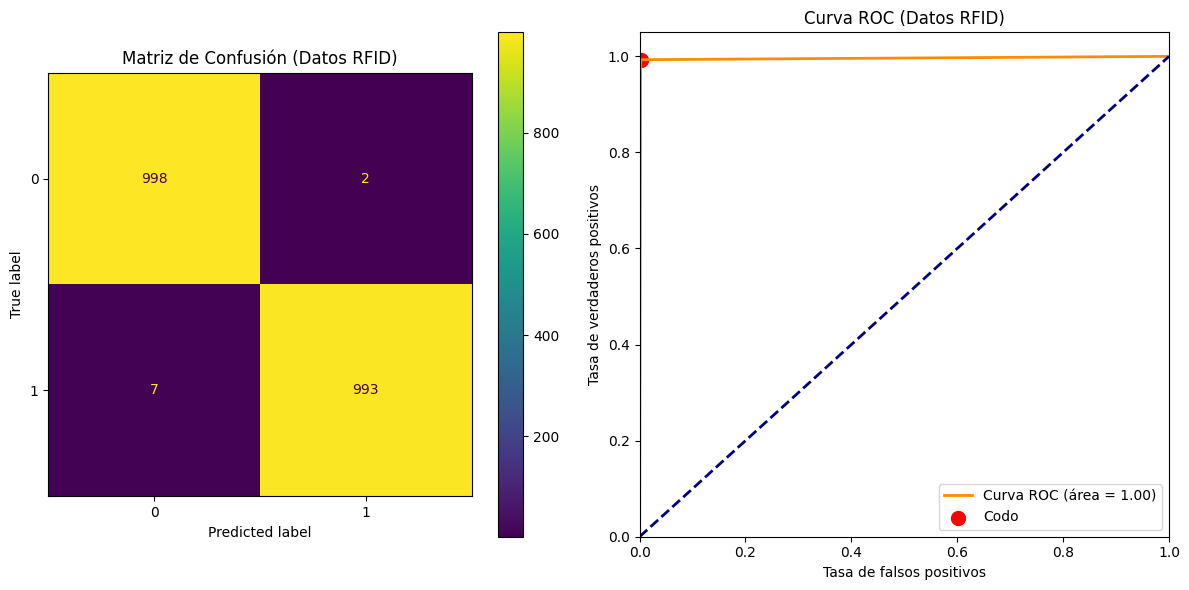

In [ ]:
# Cargar el conjunto de datos 📊
df = pd.read_csv('/content/inventario_con_datos_rfid_222.csv')

# Convertimos las variables categóricas en variables dummy 🏷️
df = pd.get_dummies(df, columns=['Categoria', 'Estacion'], drop_first=True)

# Definir y normalizar las características (X) y la variable objetivo (y) 🎯
X = df[['InventarioInicial', 'InventarioRecepcion', 'InventarioVentas']]
y = df['InventarioAlmacenamiento']

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
X_train, X_test, y_train, y_test = train_test_split(X_scaled, y, test_size=0.2, random_state=42)

# Definir los regresores 🌳📈
regressors = {
    'RandomForest': RandomForestRegressor(random_state=42),
    'DecisionTree': DecisionTreeRegressor(random_state=42),
    'GradientBoosting': GradientBoostingRegressor(random_state=42),
    'SVR': SVR(),
    'KNN': KNeighborsRegressor()
}

best_regressor = None
best_rmse = float('inf')

# Evaluar el rendimiento de cada regresor para identificar el mejor modelo 🏆
for name, reg in regressors.items():
    reg.fit(X_train, y_train)
    y_pred = reg.predict(X_test)

    mse = mean_squared_error(y_test, y_pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_test, y_pred)
    mae = mean_absolute_error(y_test, y_pred)

    print(f"Regresor: {name} (Datos RFID)")
    print(f"Error Absoluto Medio (MAE): {mae}")
    print(f"Error Cuadrático Medio (MSE): {mse}")
    print(f"Raíz del Error Cuadrático Medio (RMSE): {rmse}")
    print(f"Coeficiente de Determinación (R²): {r2}")
    print("\n")

    if rmse < best_rmse:
        best_rmse = rmse
        best_regressor = reg

# Guardar las predicciones del mejor regresor 💾
best_pred = best_regressor.predict(X_test)
predicciones = pd.DataFrame({'Inventario_RFID': best_pred, 'Real': y_test})
predicciones.to_csv('/content/predicciones_inventario_rfid.csv', index=False)

print("Predicciones guardadas en 'predicciones_inventario_rfid.csv'")
print(f"Mejor regresor (Datos RFID): {best_regressor}")
print(f"Mejor RMSE (Datos RFID): {best_rmse}")

print("==================================================================")
# Visualizar los primeros 10 datos del DataFrame de predicciones 🔍
print(predicciones.head(10))

# Crear la matriz de confusión y la curva ROC ❌⭕📉
# Convertir a clasificación binaria para la matriz de confusión y curva ROC
y_test_bin = y_test > y_test.median()
y_pred_bin = best_pred > y_test.median()

# Curva ROC
# Encuentra el punto más cercano al (0,1) en la curva ROC
codo_idx = np.argmax(tpr - fpr)
# Coordenadas del punto de codo
codo_fpr = fpr[codo_idx]
codo_tpr = tpr[codo_idx]

# Crear una figura y dos subgráficos
fig, axes = plt.subplots(1, 2, figsize=(12, 6))
# Matriz de confusión
cm = confusion_matrix(y_test_bin, y_pred_bin)
disp = ConfusionMatrixDisplay(confusion_matrix=cm)
disp.plot(ax=axes[0])  # Mostrar en el primer subgráfico
axes[0].set_title("Matriz de Confusión (Datos RFID)")

# Gráfico de la curva ROC
axes[1].plot(fpr, tpr, color='darkorange', lw=2, label=f'Curva ROC (área = {roc_auc:.2f})')
axes[1].scatter(codo_fpr, codo_tpr, color='red', label='Codo', s=100)  # Agregar el punto de codo
axes[1].plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
axes[1].set_xlim([0.0, 1.0])
axes[1].set_ylim([0.0, 1.05])
axes[1].set_xlabel('Tasa de falsos positivos')
axes[1].set_ylabel('Tasa de verdaderos positivos')
axes[1].set_title('Curva ROC (Datos RFID)')
axes[1].legend(loc="lower right")
plt.tight_layout()
# Mostrar los gráficos
plt.show()